In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import loompy as lp

In [2]:
adata1=sc.read_h5ad("/home/julia/data/placodes/ANDYs_notebboks/h5ad/E9_E10_E11_QC_SCRUBLET_020.h5ad")

In [3]:
adata_sub=sc.read_h5ad("/home/julia/data/placodes/ANDYs_notebboks/Scenic_neuro_cl6/sub_cl6.h5ad")

/home/julia/miniconda3/envs/scenicplus/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


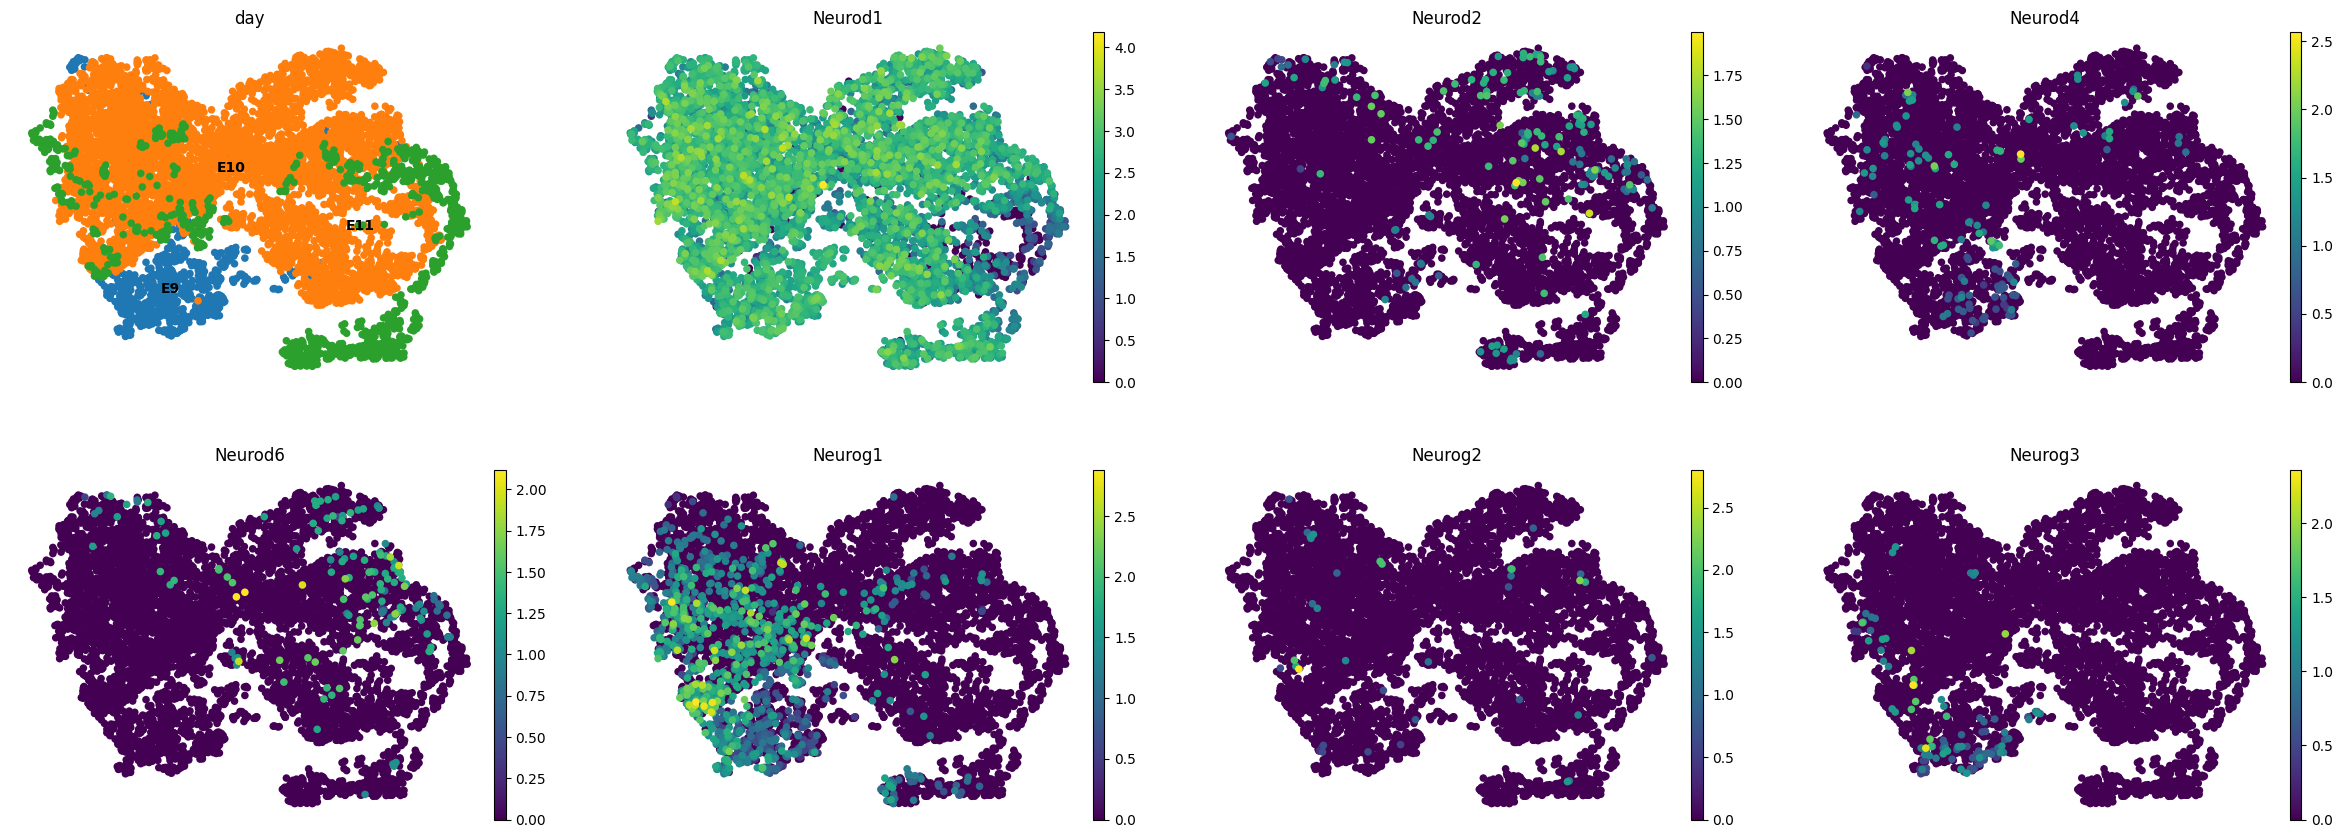

In [4]:
sc.pl.umap(adata_sub, color=["day",  'Neurod1', 'Neurod2', 'Neurod4', 'Neurod6', 'Neurog1', 'Neurog2', 'Neurog3'], size=120, frameon=False, legend_loc='on data')

In [5]:
# Select cells from adata that are present in adata_sub
common_cells = adata1.obs_names.intersection(adata_sub.obs_names)

adata = adata1[common_cells, :].copy()

print("Original:", adata1.shape)
print("Subset:", adata_sub.shape)
print("SCENIC:", adata.shape)

Original: (94890, 32285)
Subset: (7153, 32285)
SCENIC: (7153, 32285)


In [7]:
adata.obs_names_make_unique()

In [9]:
adata

AnnData object with n_obs × n_vars = 7153 × 32285
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: 'counts'

In [10]:
f_loom_path_scenic = "All_filtered_scenic.loom"
f_anndata_path = "anndata.h5ad"
f_pyscenic_output = "All_pyscenic_output.loom"
f_final_loom = 'All_scenic_integrated-output.loom'

In [11]:

row_attrs = {
    "Gene": np.array(adata.var_names) ,
}
col_attrs = {
    "CellID": np.array(adata.obs_names) ,
    "nGene": np.array( np.sum(adata.X.transpose()>0 , axis=0)).flatten() ,
    "nUMI": np.array( np.sum(adata.X.transpose() , axis=0)).flatten() ,
}
lp.create( f_loom_path_scenic, adata.X.transpose(), row_attrs, col_attrs)

In [12]:
pwd

'/mnt/data/julia/placodes/ANDYs_notebboks/Scenic_neuro_cl6'

In [13]:
!/home/julia/miniconda3/envs/scenicplus/bin/pyscenic grn /mnt/data/julia/placodes/ANDYs_notebboks/Scenic_neuro_cl6/All_filtered_scenic.loom /home/julia/data/Scenic_database/Mouse/TF/allTFs_mm.txt -o adj_1.csv  --num_workers 30


2026-10-22 11:59:04,819 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2026-10-22 11:59:07,716 - pyscenic.cli.pyscenic - INFO - Inferring regulatory networks.
2026-10-22 11:59:18,897 - distributed.diskutils - INFO - Found stale lock file and directory '/tmp/dask-worker-space/worker-wqqztcu1', purging
2026-10-22 11:59:18,901 - distributed.diskutils - INFO - Found stale lock file and directory '/tmp/dask-worker-space/worker-jaudccyg', purging
2026-10-22 11:59:18,902 - distributed.diskutils - INFO - Found stale lock file and directory '/tmp/dask-worker-space/worker-85djb9dk', purging
2026-10-22 11:59:18,903 - distributed.diskutils - INFO - Found stale lock file and directory '/tmp/dask-worker-space/worker-sio1cv0e', purging
2026-10-22 11:59:18,908 - distributed.diskutils - INFO - Found stale lock file and directory '/tmp/dask-worker-space/worker-rj0wt02o', purging
2026-10-22 11:59:18,909 - distributed.diskutils - INFO - Found stale lock file and directory '/tmp/dask-worker-

In [14]:
adjacencies = pd.read_csv("adj_1.csv", index_col=False)

In [15]:
adjacencies

,TF,target,importance
0,Hmx1,Nrp1,2.165198e+02
1,Hmgb2,Ube2c,1.644029e+02
2,Hmgb2,Top2a,1.558890e+02
3,Irx1,Hmx1,1.483938e+02
4,Hmgb2,Cks2,1.413853e+02
...,...,...,...
6063956,Ssbp3,Hbb-bh1,5.790141e-19
6063957,Zbtb44,Hba-a1,2.574251e-19
6063958,Etv6,Hba-a1,1.618752e-19
6063959,Zbtb24,Hba-x,5.258459e-20


In [16]:
f_tfs='/home/julia/data/Scenic_database/Mouse/TF/allTFs_mm.txt'

In [17]:
import glob
# ranking databases
f_db_glob = "/home/julia/data/Scenic_database/Mouse/Gene_based/*feather"
f_db_names = ' '.join( glob.glob(f_db_glob) )

In [19]:
!/home/julia/miniconda3/envs/scenicplus/bin/pyscenic ctx adj_1.csv \
    {f_db_names} \
    --annotations_fname /home/julia/data/Scenic_database/Mouse/Motif2TF/motifs-v10nr_clust-nr.mgi-m0.001-o0.0.tbl \
    --expression_mtx_fname /mnt/data/julia/placodes/ANDYs_notebboks/Scenic_neuro_cl6/All_filtered_scenic.loom \
    --output reg.csv \
    --mask_dropouts \
    --num_workers 30


2026-10-22 15:24:53,837 - pyscenic.cli.pyscenic - INFO - Creating modules.

2026-10-22 15:24:56,520 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2026-10-22 15:25:00,307 - pyscenic.utils - INFO - Calculating Pearson correlations.

2026-10-22 15:25:01,729 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [True].

2026-10-22 15:25:36,942 - pyscenic.utils - INFO - Creating modules.

2026-10-22 15:27:51,262 - pyscenic.cli.pyscenic - IN

In [20]:
!/home/julia/miniconda3/envs/scenicplus/bin/pyscenic aucell \
    {f_loom_path_scenic} \
    reg.csv \
    --output {f_pyscenic_output} \
    --num_workers 40


2026-10-22 15:40:03,132 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2026-10-22 15:40:06,119 - pyscenic.cli.pyscenic - INFO - Loading gene signatures.
Create regulons from a dataframe of enriched features.
Additional columns saved: []

2026-10-22 15:40:09,095 - pyscenic.cli.pyscenic - INFO - Calculating cellular enrichment.

2026-10-22 15:40:35,440 - pyscenic.cli.pyscenic - INFO - Writing results to file.
/home/julia/miniconda3/envs/scenicplus/lib/python3.8/site-packages/pyscenic/cli/utils.py:347: FutureWarning: iteritems is deprecated and will be removed in a future version. Use .items instead.
  for name, threshold in auc_thresholds.iteritems()


##